In [11]:
import pandas as pd
print(pd.__version__)

3.0.5


In [12]:
df = pd.read_csv("tested.csv")

In [13]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [14]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [15]:
df["Age"] = df["Age"].fillna(df["Age"].median())

df["Fare"] = df["Fare"].fillna(df["Fare"].median())

df = df.drop("Cabin", axis=1)

In [16]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

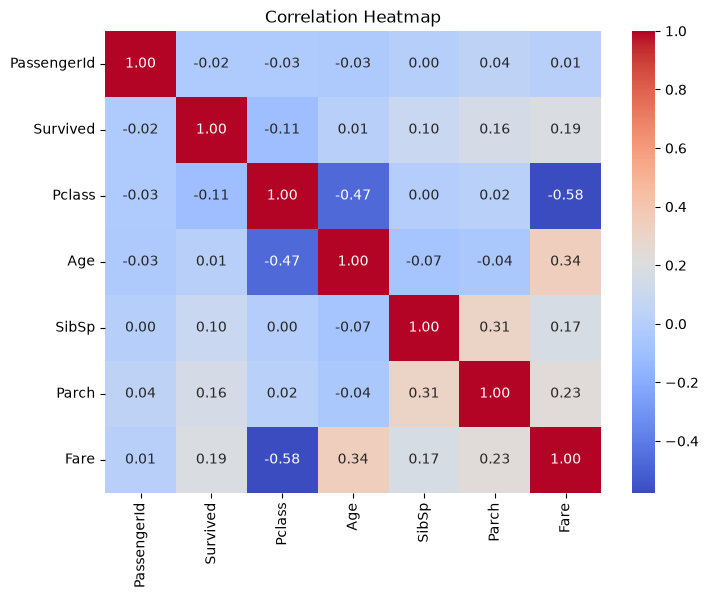

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap ='coolwarm' , fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

In [18]:
age_mean = df["Age"].mean()
age_std = df["Age"].std()

fare_mean = df["Fare"].mean()
fare_std = df["Fare"].std()

df["Age_standardized"] = (df["Age"] - age_mean) / age_std
df["Fare_standardized"] = (df["Fare"] - fare_mean) / fare_std

df[["Age", "Age_standardized", "Fare", "Fare_standardized"]].head()

,Age,Age_standardized,Fare,Fare_standardized
0,34.5,0.385769,7.8292,-0.496818
1,47.0,1.369729,7.0000,-0.511665
2,62.0,2.550481,9.6875,-0.463545
3,27.0,-0.204607,8.6625,-0.481898
4,22.0,-0.598191,12.2875,-0.416992


In [19]:
print("Age Mean:", df["Age_standardized"].mean())
print("Age Standard Deviation:", df["Age_standardized"].std())

print("Fare Mean:", df["Fare_standardized"].mean())
print("Fare Standard Deviation:", df["Fare_standardized"].std())

Age Mean: 6.586969141316718e-17
Age Standard Deviation: 1.0
Fare Mean: 8.074349270001139e-17
Fare Standard Deviation: 1.0


In [20]:
age_min = df["Age"].min()
age_max = df["Age"].max()

fare_min = df["Fare"].min()
fare_max = df["Fare"].max()

df["Age_normalized"] = (df["Age"] - age_min) / (age_max - age_min)
df["Fare_normalized"] = (df["Fare"] - fare_min) / (fare_max - fare_min)

df[["Age", "Age_normalized", "Fare", "Fare_normalized"]].head()

,Age,Age_normalized,Fare,Fare_normalized
0,34.5,0.452723,7.8292,0.015282
1,47.0,0.617566,7.0000,0.013663
2,62.0,0.815377,9.6875,0.018909
3,27.0,0.353818,8.6625,0.016908
4,22.0,0.287881,12.2875,0.023984


In [21]:
print("Age Minimum:", df["Age_normalized"].min())
print("Age Maximum:", df["Age_normalized"].max())

print("Fare Minimum:", df["Fare_normalized"].min())
print("Fare Maximum:", df["Fare_normalized"].max())

Age Minimum: 0.0
Age Maximum: 1.0
Fare Minimum: 0.0
Fare Maximum: 1.0
